# 02 · Tokenizer walkthrough

Goal: understand how text becomes integers, step by step, before we build on it.
Run top to bottom (Shift+Enter). Cells marked **Predict** want a guess *before* you run them.

1. Text is bytes
2. Learn BPE merges by hand (pure Python)
3. Our real tokenizer (HF `tokenizers`) vs your hand-made one
4. No unknown tokens
5. GPT-2's tokenizer (tiktoken) and why vocab size matters for a tiny model

In [1]:
from collections import Counter
from pathlib import Path

from tinygpt.tokenizer import BPETokenizer, train_bpe

text = Path("../tests/fixtures/sample_stories.txt").read_text(encoding="utf-8")
print(len(text), "characters,", len(text.encode("utf-8")), "bytes")
print(text[:200])

1617 characters, 1617 bytes
Once upon a time, there was a little fox named Pip. Pip lived near a river with his mother. Every morning, Pip ran to the water and looked at the fish. "I want to catch one," he said. His mother smile


## 1 · Text is bytes
A computer stores "🦊" as UTF-8 bytes. Byte-level BPE starts from these: the base vocabulary is the
256 possible byte values, so **every** string can be represented. Characters outside ASCII take
several bytes.

In [2]:
for s in ["a", "é", "日", "🦊"]:
    print(repr(s), "->", list(s.encode("utf-8")))

'a' -> [97]
'é' -> [195, 169]
'日' -> [230, 151, 165]
'🦊' -> [240, 159, 166, 138]


## 2 · BPE by hand
The algorithm:
1. Start with the text as a list of byte values (0..255).
2. Count every adjacent pair.
3. Replace the most frequent pair with a **new id** (256, 257, ...). Remember the merge.
4. Repeat.

This is a simplified version (no regex pre-splitting into words), good enough to see the idea.

In [3]:
def pair_counts(ids):
    return Counter(zip(ids, ids[1:]))

def merge(ids, pair, new_id):
    out, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
            out.append(new_id)
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out

# tiny example you can check on paper
print(pair_counts([1, 2, 1, 2, 3]))      # (1,2) appears twice
print(merge([1, 2, 1, 2, 3], (1, 2), 99))  # -> [99, 99, 3]

Counter({(1, 2): 2, (2, 1): 1, (2, 3): 1})
[99, 99, 3]


In [4]:
ids = list(text.encode("utf-8"))
vocab = {i: bytes([i]) for i in range(256)}   # id -> the bytes it stands for
merges = []                                    # learned, in order

for new_id in range(256, 256 + 40):
    counts = pair_counts(ids)
    pair, n = counts.most_common(1)[0]
    ids = merge(ids, pair, new_id)
    vocab[new_id] = vocab[pair[0]] + vocab[pair[1]]
    merges.append(pair)
    if new_id < 256 + 15 or new_id % 10 == 0:
        print(f"merge {new_id - 255:>2}: {vocab[pair[0]]!r:>8} + {vocab[pair[1]]!r:<8} -> {vocab[new_id]!r:<10} ({n}x)")

print("\nsequence length:", len(text.encode("utf-8")), "->", len(ids))

merge  1:     b'e' + b' '     -> b'e '      (55x)
merge  2:     b'd' + b' '     -> b'd '      (49x)
merge  3:     b't' + b'h'     -> b'th'      (33x)
merge  4:     b'.' + b' '     -> b'. '      (26x)
merge  5:     b' ' + b'a'     -> b' a'      (24x)
merge  6:     b' ' + b'th'    -> b' th'     (21x)
merge  7:     b'e' + b'r'     -> b'er'      (19x)
merge  8:     b't' + b' '     -> b't '      (18x)
merge  9:     b' ' + b's'     -> b' s'      (18x)
merge 10:     b'e' + b'd '    -> b'ed '     (17x)
merge 11:     b'y' + b' '     -> b'y '      (17x)
merge 12:     b'n' + b'd '    -> b'nd '     (17x)
merge 13:     b'w' + b'a'     -> b'wa'      (16x)
merge 14:   b' th' + b'e '    -> b' the '   (16x)
merge 15:     b'o' + b' '     -> b'o '      (14x)
merge 25:    b'wa' + b's'     -> b'was'     (8x)
merge 35:     b'l' + b'i'     -> b'li'      (6x)

sequence length: 1617 -> 1051


**Predict:** which merges come first? (Hint: the most common letter pairs and space+letter pairs.)
Notice later merges build on earlier ones: `t`+`h` -> `th`, then `th`+`e` -> `the`.

### Encoding replays the merges *in the order they were learned*

In [5]:
def my_encode(s):
    ids = list(s.encode("utf-8"))
    for new_id, pair in zip(range(256, 256 + len(merges)), merges):
        ids = merge(ids, pair, new_id)
    return ids

def my_decode(ids):
    return b"".join(vocab[i] for i in ids).decode("utf-8", errors="replace")

s = "Once upon a time, a little fox"
enc = my_encode(s)
print(enc)
print([vocab[i] for i in enc])
print(my_decode(enc) == s)

[79, 110, 99, 256, 117, 112, 271, 278, 116, 105, 109, 101, 44, 278, 290, 116, 116, 108, 256, 102, 111, 120]
[b'O', b'n', b'c', b'e ', b'u', b'p', b'on', b' a ', b't', b'i', b'm', b'e', b',', b' a ', b'li', b't', b't', b'l', b'e ', b'f', b'o', b'x']
True


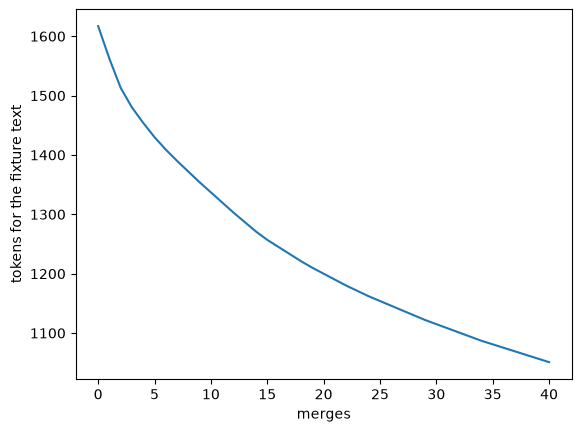

In [6]:
# How compression grows with the number of merges
import matplotlib.pyplot as plt

lengths, cur = [], list(text.encode("utf-8"))
lengths.append(len(cur))
for new_id, pair in zip(range(256, 256 + len(merges)), merges):
    cur = merge(cur, pair, new_id)
    lengths.append(len(cur))

plt.plot(lengths)
plt.xlabel("merges"); plt.ylabel("tokens for the fixture text"); plt.show()

## 3 · Our real tokenizer
`train_bpe` does the same thing with the HF `tokenizers` library (fast, Rust), plus a regex
pre-split so merges never cross word boundaries. Vocab 512 = 256 bytes + 1 special + 255 merges.

In [7]:
tok = train_bpe(text.split("\n\n"), vocab_size=512)
print(tok.vocab_size, tok.eot_id)

def show(s):
    ids = tok.encode(s)
    print(f"{s!r}: {len(ids)} tokens")
    print("   ", [tok.decode([i]) for i in ids])

for s in ["the", " the", "The", "Pip", "Once upon a time, a little fox"]:
    show(s)

512 0
'the': 2 tokens
    ['t', 'he']
' the': 1 tokens
    [' the']
'The': 1 tokens
    ['The']
'Pip': 2 tokens
    ['Pi', 'p']
'Once upon a time, a little fox': 12 tokens
    ['On', 'ce', ' u', 'pon', ' a', ' tim', 'e', ',', ' a', ' little', ' f', 'ox']


**Predict:** how many tokens will `"🦊"` take? (It never appeared in the training text.)

In [8]:
show("🦊")

'🦊': 4 tokens
    ['�', '�', '�', '�']


In [9]:
# Compare with your hand-made merges on the same sentence
s = "Once upon a time, a little fox"
print("hand-made (40 merges):", len(my_encode(s)), "tokens")
print("HF (255 merges):      ", len(tok.encode(s)), "tokens")

hand-made (40 merges): 22 tokens
HF (255 merges):       12 tokens


## 4 · No unknown tokens
Your first notebook needed `<|unk|>` for words outside the vocabulary. Here nothing is unknown.

In [10]:
for s in ["Akwirw ier", "日本語", "🦊🌳", "Hello<|endoftext|>World"]:
    ids = tok.encode(s)
    print(repr(s), "->", ids, "-> round trip ok:", tok.decode(ids) == s)

'Akwirw ier' -> [33, 75, 87, 304, 87, 221, 73, 271] -> round trip ok: True
'日本語' -> [163, 246, 99, 163, 251, 106, 165, 104, 253] -> round trip ok: True
'🦊🌳' -> [173, 254, 100, 233, 173, 254, 235, 112] -> round trip ok: True
'Hello<|endoftext|>World' -> [453, 79, 0, 55, 323, 320] -> round trip ok: True


## 5 · GPT-2's tokenizer (tiktoken) and why vocab size matters
Needs network once to fetch the vocab file. GPT-2's tokenizer is trained on a huge web corpus, so it
needs fewer tokens per text. But the embedding table costs `vocab_size x d_model` parameters, and the
output layer is tied to it.

In [11]:
import tiktoken

gpt2 = tiktoken.get_encoding("gpt2")
s = "Once upon a time, a little fox named Pip lived near the river."
print("gpt2:", len(gpt2.encode(s)), "tokens ->", [gpt2.decode([i]) for i in gpt2.encode(s)])
print("ours:", len(tok.encode(s)), "tokens (vocab 512 on 5 stories; real run will be 4096 on TinyStories)")

d_model = 256
for name, v in [("our small run", 4096), ("GPT-2", gpt2.n_vocab)]:
    print(f"{name:>14}: vocab {v:>6} -> embedding {v * d_model / 1e6:5.2f}M parameters")
print("rest of the 'small' model (6 blocks + positions): about 4.8M parameters")

gpt2: 15 tokens -> ['Once', ' upon', ' a', ' time', ',', ' a', ' little', ' fox', ' named', ' Pip', ' lived', ' near', ' the', ' river', '.']
ours: 20 tokens (vocab 512 on 5 stories; real run will be 4096 on TinyStories)
 our small run: vocab   4096 -> embedding  1.05M parameters
         GPT-2: vocab  50257 -> embedding 12.87M parameters
rest of the 'small' model (6 blocks + positions): about 4.8M parameters


## Questions to answer before moving on
1. Why does `" the"` become one token earlier than `"the"`?
2. With a 50k vocab the model would be mostly embedding table. Is that a problem for a 6M model
   trained on 40M tokens? (Think: how many examples does each of 50k rows get to learn from?)
3. Could we use tiktoken anyway? What would it cost in parameters and in training speed
   (the output projection runs over `vocab_size` logits at every position)?

**Decision point for you:** keep our own 4096 BPE (trained on TinyStories, small embedding) or switch
to GPT-2's tokenizer. Tell me which after you have run this.